# 02 相机校准

本 Notebook 对应 **scripts/calibration** 的校准流水线，用于 3D 重建前的相机校准与质量检查。

## 流程概览

1. **Step 1**：从标定视频抽帧
2. **Step 2**：手动标注 2D 坐标（需在终端运行交互工具）
3. **Step 3**：训练校准模型
4. **Step 3b**：校准物 3D 模型可视化（珠子着色，远处透明）
5. **Step 4**：验证校准质量（重投影误差）
6. **使用模型**：2D → 3D 三角化

详见 `scripts/calibration/README.md`。

## Step 1：从标定视频抽帧

从标定视频中抽取一帧用于手动标注。脚本：`scripts/calibration/extract_calib_frames.py`  
输入目录需包含 `top_cam/`, `side1_cam/`, `side2_cam/` 子目录及对应视频。

In [ ]:
# Step 1：抽帧（直接在此设定路径，本 cell 可单独运行）

import subprocess
import sys
from pathlib import Path

# 项目目录（绝对路径，可修改）
project_dir = r"H:\medaka-mating-pipeline"
script = Path(project_dir) / "scripts" / "calibration" / "extract_calib_frames.py"

input_dir = Path(r"H:\calibration_raw\cali_20251217\cali_251217_way1")
output_dir = Path(r"H:\calibration_raw\cali_20251217\cali_251217_way1_pic")
frame_idx = 100

if input_dir.exists() and script.exists():
    subprocess.run([sys.executable, str(script), "--input", str(input_dir), "--output", str(output_dir), "--frame", str(frame_idx)], cwd=project_dir)
    print("抽帧完成，输出目录:", output_dir)
else:
    print("跳过：输入目录不存在", input_dir) if not input_dir.exists() else print("脚本不存在:", script)
    print("命令行示例：")
    print(f'  python scripts/calibration/extract_calib_frames.py --input "{input_dir}" --output "{output_dir}" --frame {frame_idx}')

抽帧完成，输出目录: H:\calibration_raw\cali_20251222\cali_251217_way1_pic


## Step 2：手动标注 2D 坐标

使用交互式工具在图像上标注校准点。**必须在终端中运行**（非 Notebook 内）。

先标记四个顶点，从黑色角顺时针标注。
从粉色最低的珠子开始标记到粉色最高珠子，按粉黄蓝黑橙紫银颜色依次标注。

交互操作：左键标注、右键删除,自动保存。标记完一张之后点×，标记下一张。

In [ ]:
python "H:\medaka-mating-pipeline\scripts\calibration\detect_board.py" --folder "H:\calibration_raw\cali_20251217\cali_251217_way1_pic" --output "H:\calibration_making\cali_251217_way1"

## Step 3：训练校准模型

使用标注的 2D 坐标与 3D 模板训练回归模型（多项式 / 随机森林等）。  


In [ ]:
# Step 3：训练校准模型（2D 标注已完成时运行）
# 为每个 way 分别训练模型（本 cell 可单独运行，无需先运行前面 cell）

import sys
import subprocess
from pathlib import Path

# 项目目录（绝对路径，可修改）
project_dir = r"H:\medaka-mating-pipeline"
script_path = Path(project_dir) / "scripts" / "calibration" / "solve_intrinsics.py"

# 路径可在此修改
calibration_folder = Path(r"D:\calibration_raw\cali_20251217")
image_coords_folder = Path(r"D:\calibration_marking\cali_251217_way1")
output_folder = Path(r"D:\calibration_model\cali_251217_way1")
results_root = Path(r"D:\\calibration_qc\\cali_251217_way1")


coords_path = Path(image_coords_folder)
coords_files = list(coords_path.glob("*_image_coords.txt")) if coords_path.exists() else []

if coords_files:
    cmd = [
        sys.executable,
        str(script_path),
        "--calibration_folder", str(calibration_folder),
        "--image_coords_folder", str(image_coords_folder),
        "--output_folder", str(output_folder),
        "--results_root", str(results_root),
        "--alpha_range", "1e-6", "1e-5", "1e-4", "0.001", "0.01",
        "--poly_deg_range", "1", "2", "3", "4",
        "--no_auto_detect",
    ]
    print("执行命令:", " ".join(cmd))
    print("模型将保存到:", output_folder)
    result = subprocess.run(cmd, cwd=project_dir, capture_output=True, text=True)
    print(result.stdout)
    if result.stderr:
        print("stderr:", result.stderr)
    if result.returncode != 0:
        print(f"[错误] 训练脚本退出码: {result.returncode}")
    else:
        # 检查是否生成了模型
        models_dir = Path(output_folder)
        joblib_files = list(models_dir.rglob("imCoords_to_XYZ.joblib")) if models_dir.exists() else []
        if joblib_files:
            print(f"\n[成功] 已生成 {len(joblib_files)} 个模型:")
            for f in joblib_files:
                print(f"  - {f}")
        else:
            print("\n[警告] 未找到 imCoords_to_XYZ.joblib，请检查上方输出是否有错误")
else:
    print("跳过：未找到 2D 标注文件 (*_image_coords.txt)")
    print("image_coords_folder:", image_coords_folder, "(存在)" if coords_path.exists() else "(不存在)")

执行命令: h:\medaka-mating-pipeline\.venv\Scripts\python.exe H:\medaka-mating-pipeline\scripts\calibration\solve_intrinsics.py --calibration_folder H:\calibration_raw\cali_20251217 --image_coords_folder H:\calibration_marking\cali_251217_way1 --output_folder H:\calibration_model\cali_251217_way1 --results_root H:\calibration_qc\cali_251217_way1 --alpha_range 1e-6 1e-5 1e-4 0.001 0.01 --poly_deg_range 1 2 3 4 --no_auto_detect
模型将保存到: H:\calibration_model\cali_251217_way1
Camera Calibration Pipeline
Processing 1 calibration set(s)...

######################################################################
# [1/1] cali_20251217
######################################################################
Calibration folder: H:\calibration_raw\cali_20251217
Image coords folder: H:\calibration_marking\cali_251217_way1
Output folder: H:\calibration_model\cali_251217_way1
  Saved: H:\calibration_model\cali_251217_way1\imCoords_to_XYZ.joblib
  Saved: H:\calibration_model\cali_251217_way1\xy_yz_to_xz.jobli

## Step 3b：生成 point_mapping（可选）

第三步只负责 **训练模型并保存 joblib**。若需要做 3D 质检（Step 4 / Step 5），
可以在这里用已训练好的 `imCoords_to_XYZ.joblib` 对所有点做一次 3D 预测，
生成 `*_point_mapping.csv`，供后续可视化使用。

In [6]:
# Step 3b：使用已训练模型生成 point_mapping CSV（模板 3D vs 模型预测 3D）
# 本 cell 可在 Step 3 训练完成后单独运行

from pathlib import Path
import sys
import subprocess

# 项目目录（绝对路径，可修改）
project_dir = Path(r"H:\medaka-mating-pipeline")
script_path = project_dir / "scripts" / "calibration" / "generate_point_mapping.py"

calibration_folder = Path(r"H:\calibration_raw\cali_20251217")
image_coords_folder = Path(r"H:\calibration_marking\cali_251217_way1")
model_folder = Path(r"H:\calibration_model\cali_251217_way1")
results_root = Path(r"H:\calibration_qc\cali_251217_way1")
way_name = "way1"

cmd = [
    sys.executable,
    str(script_path),
    "--calibration_folder", str(calibration_folder),
    "--image_coords_folder", str(image_coords_folder),
    "--model_folder", str(model_folder),
    "--way_name", way_name,
    "--results_root", str(results_root),
]

print("执行命令:", " ".join(cmd))
result = subprocess.run(cmd, cwd=project_dir)
if result.returncode == 0:
    print("Step 3b: point_mapping 已生成，保存在:")
    print(results_root)
else:
    print("[ERROR] generate_point_mapping 运行失败，请检查上方输出。")

执行命令: h:\medaka-mating-pipeline\.venv\Scripts\python.exe H:\medaka-mating-pipeline\scripts\calibration\generate_point_mapping.py --calibration_folder H:\calibration_raw\cali_20251217 --image_coords_folder H:\calibration_marking\cali_251217_way1 --model_folder H:\calibration_model\cali_251217_way1 --way_name way1 --results_root H:\calibration_qc\cali_251217_way1
Step 3b: point_mapping 已生成，保存在:
H:\calibration_qc\cali_251217_way1


## Step 4：3D校准物及预测结果可视化


Step 4 图已保存到: D:\calibration_qc\cali_251217_way1\cali_251217_way1_3d_qc.png


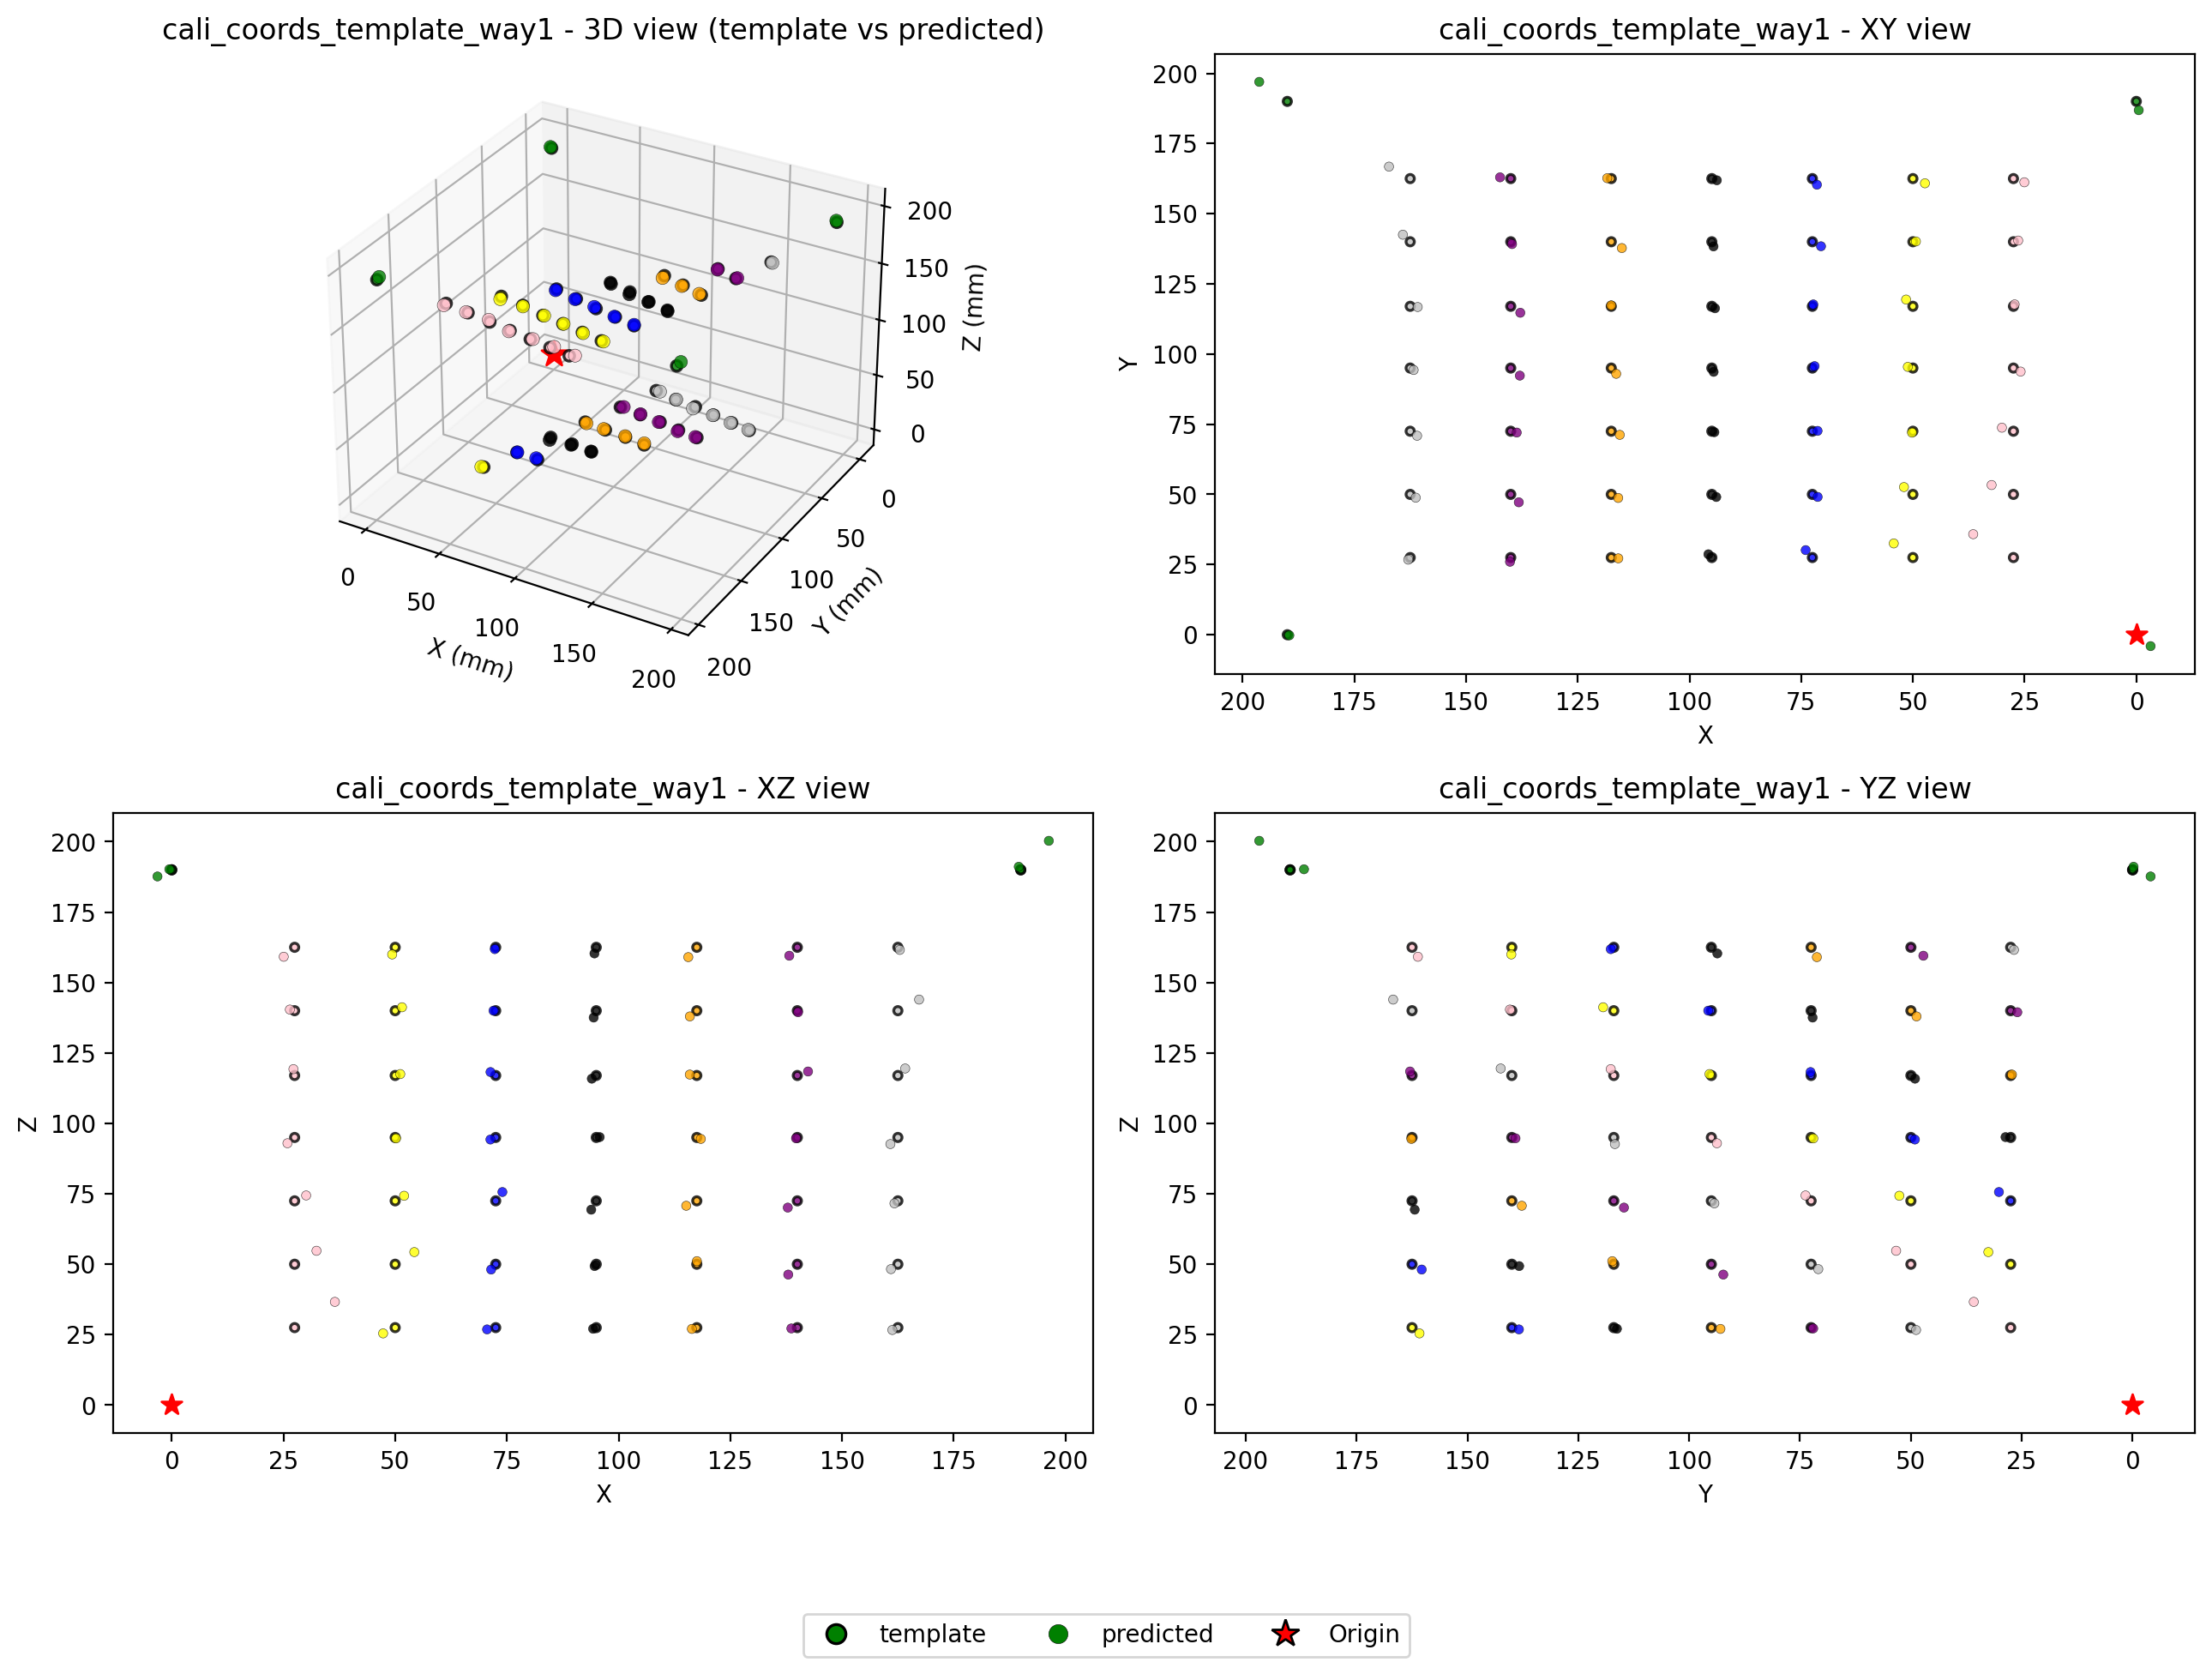

In [6]:
# Step 4：校准物 3D 模型可视化（模板 vs 预测）
# 本 cell 可单独运行，请直接修改下方所有路径

from pathlib import Path
import sys
import subprocess

# ---------- 请在此指定所有路径 ----------
project_dir = Path(r"D:\medaka-mating-pipeline")
mapping_csv = Path(r"D:\calibration_qc\cali_251217_way1\cali_20251217_point_mapping.csv")
output_png = Path(r"D:\calibration_qc\cali_251217_way1\cali_251217_way1_3d_qc.png")
template_txt = Path(r"D:\calibration_raw\cali_20251217\cali_coords_template_way1.txt")
# ---------------------------------------

script_path = project_dir / "scripts" / "calibration" / "qc_3d_template.py"
cmd = [
    sys.executable,
    str(script_path),
    "--mapping_csv", str(mapping_csv),
    "--output", str(output_png),
]
if template_txt.exists():
    cmd.extend(["--template_txt", str(template_txt)])
cmd.extend(["--way", "way1"])

cwd = project_dir.resolve() if project_dir.is_dir() else Path.cwd()
result = subprocess.run(cmd, cwd=str(cwd))
print("Step 4 图已保存到:", output_png)

# 在 notebook 内显示图片
if output_png.exists():
    from IPython.display import Image, display
    display(Image(filename=str(output_png)))
else:
    print("注：图片未生成，请检查 mapping_csv 是否存在且路径正确")

## Step 5：可视化某个模型的校准质量

比较模型预测 3D 与模板 3D 的重投影误差。  
- &lt; 5 mm：优秀；5–20 mm：良好；20–50 mm：可接受；&gt; 50 mm：需改进

能指定一个模型按要求可视化。
それぞれの点のエラー距離を計算，場所によってエラーが違うように見えるので，x,y,zそれぞれのエラー距離を青⇔赤のヒートマップに変換

Step 5 小图1 (3D) 已保存到: D:\calibration_qc\cali_251217_way1\cali_251217_way1_error_3d.png
Step 5 小图234 (XY 视角) 已保存到: D:\calibration_qc\cali_251217_way1\cali_251217_way1_error_3d_xy.png


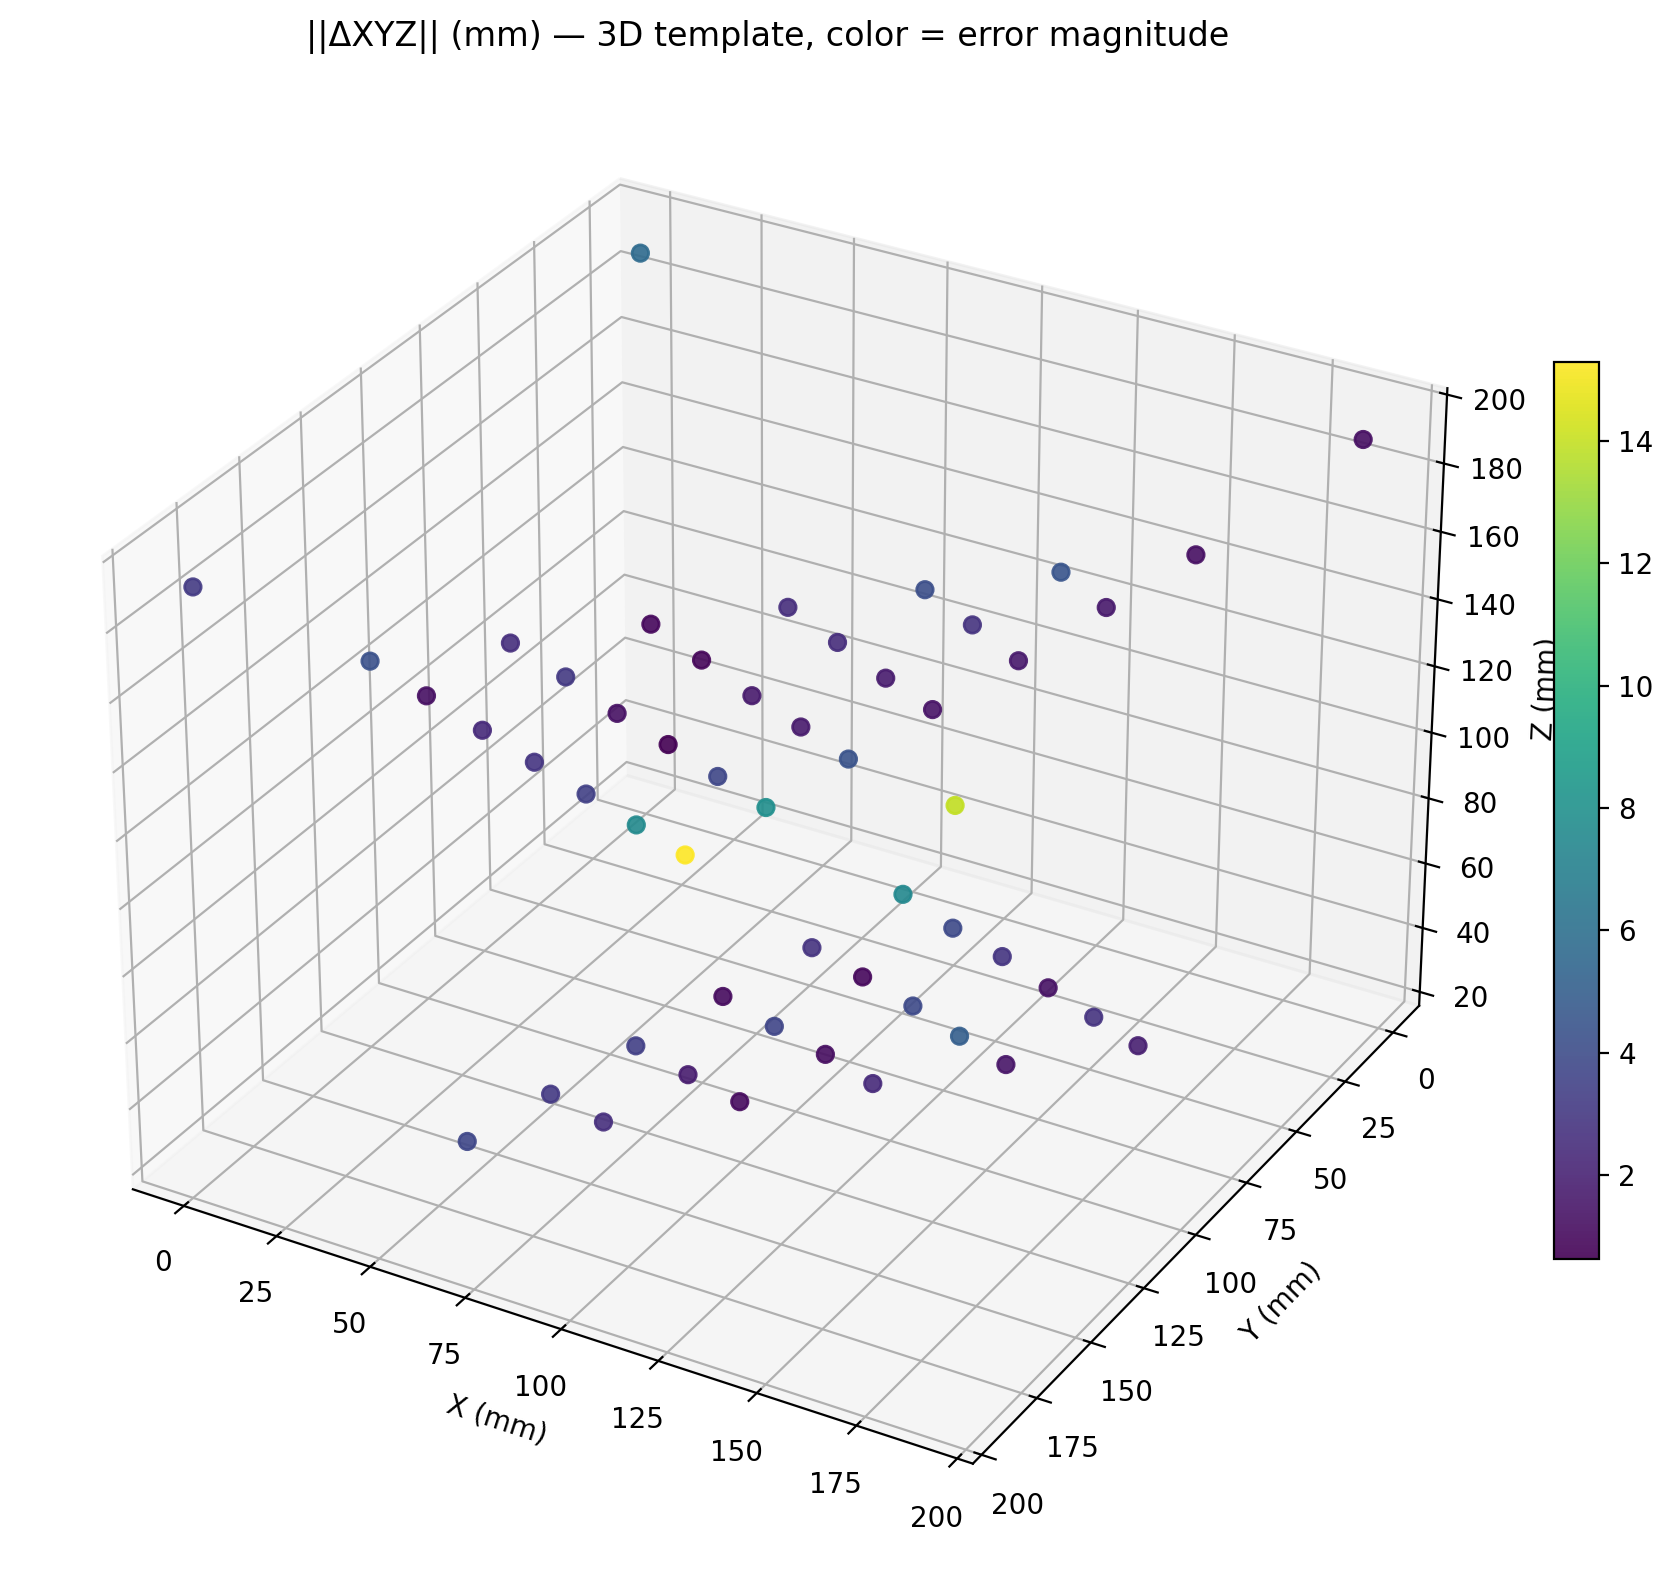

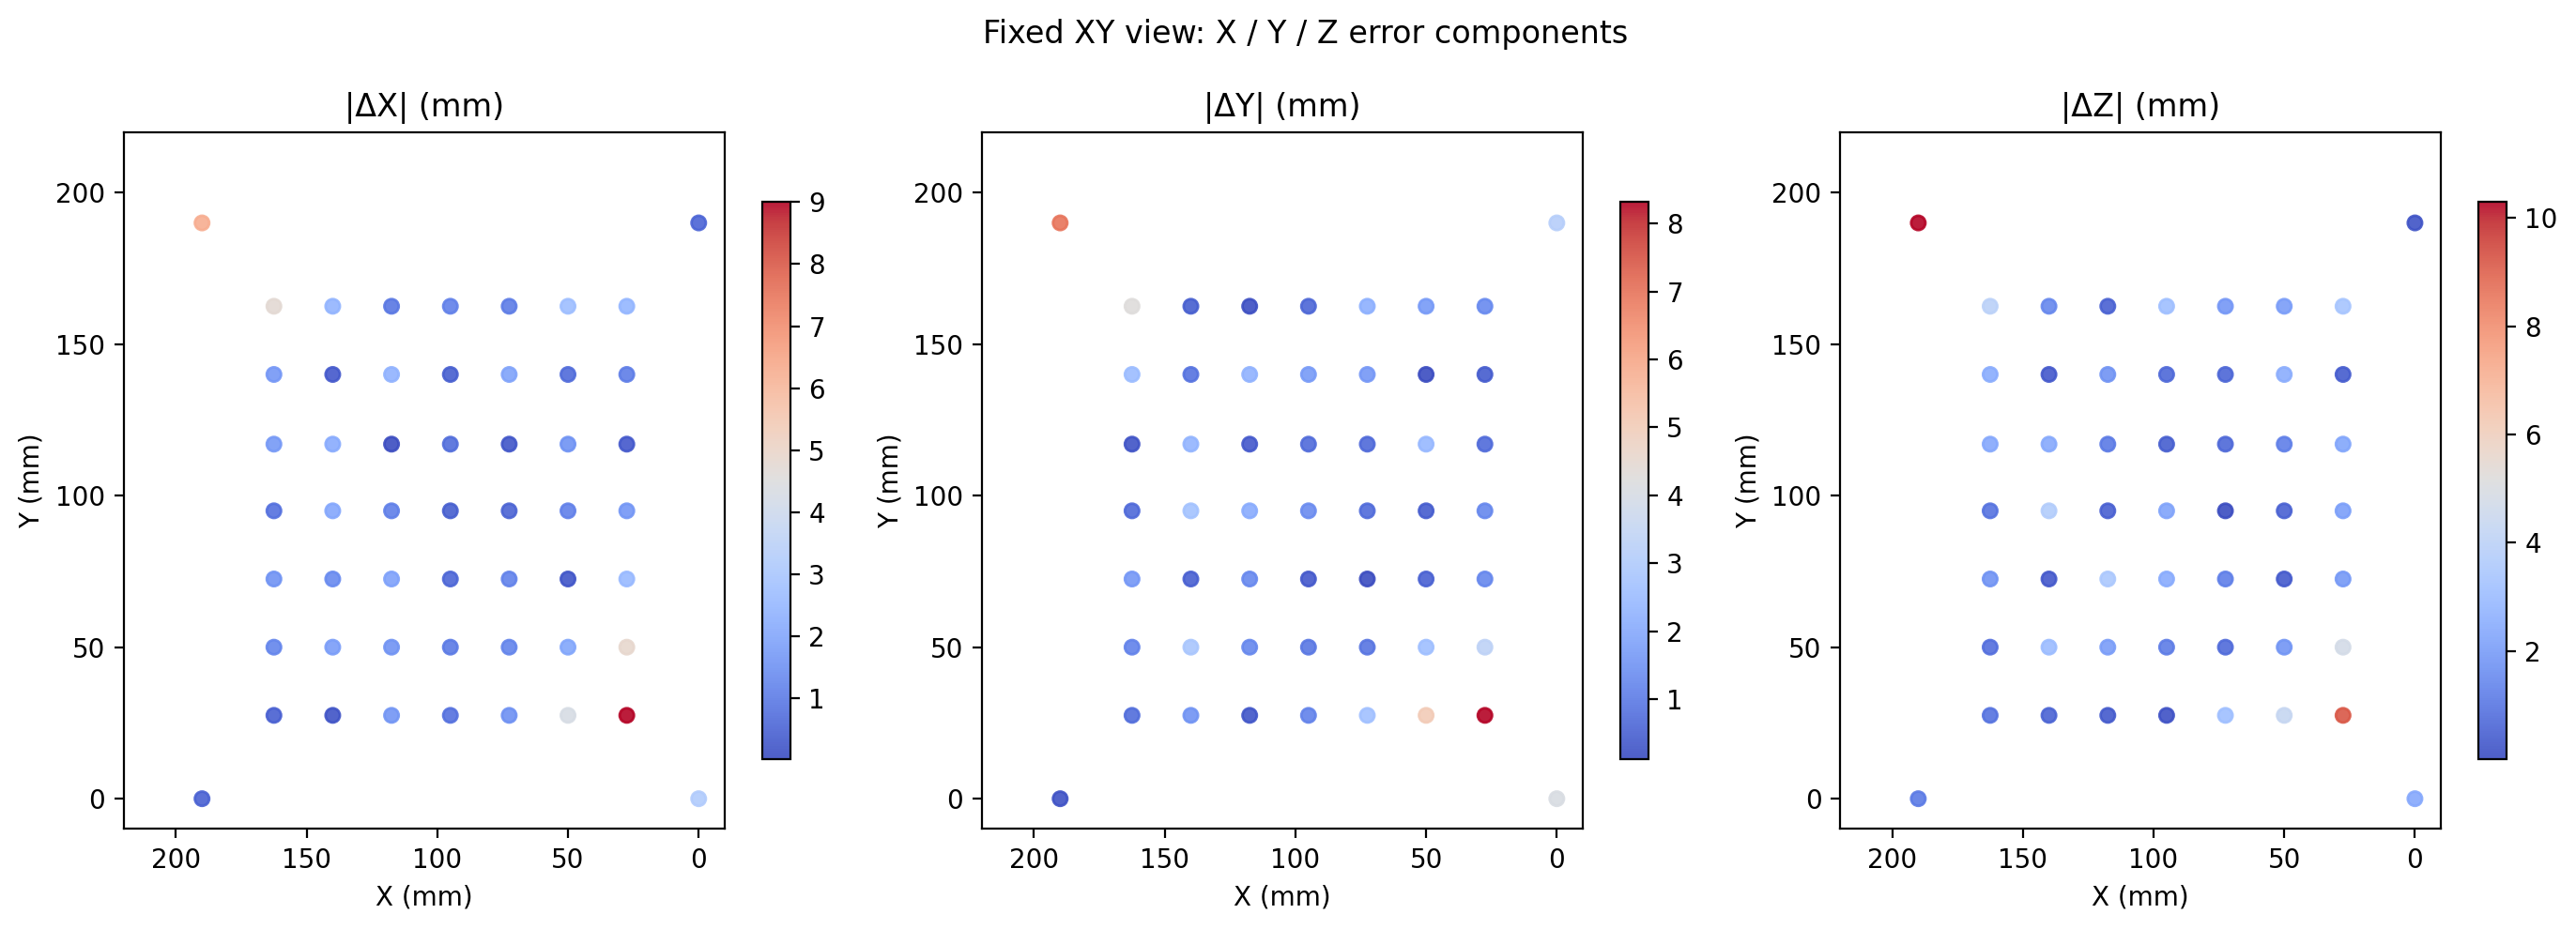

In [15]:
# Step 5：小图1 单独 3D，小图234 固定 XY 视角 |ΔX|,|ΔY|,|ΔZ|（输出两张图）
# 本 cell 可单独运行，请直接修改下方所有路径

from pathlib import Path
import sys
import subprocess

# ---------- 请在此指定所有路径 ----------
project_dir = Path(r"D:\medaka-mating-pipeline")
mapping_csv = Path(r"D:\calibration_qc\cali_251217_way1\cali_20251217_point_mapping.csv")
output_3d = Path(r"D:\calibration_qc\cali_251217_way1\cali_251217_way1_error_3d.png")
# ---------------------------------------
output_xy = output_3d.parent / (output_3d.stem + "_xy" + output_3d.suffix)

script_path = project_dir / "scripts" / "calibration" / "qc_3d_error.py"
cmd = [
    sys.executable,
    str(script_path),
    "--mapping_csv", str(mapping_csv),
    "--output", str(output_3d),
]
cwd = project_dir.resolve() if project_dir.is_dir() else Path.cwd()
subprocess.run(cmd, cwd=str(cwd))
print("Step 5 小图1 (3D) 已保存到:", output_3d)
print("Step 5 小图234 (XY 视角) 已保存到:", output_xy)

from IPython.display import Image, display
if output_3d.exists():
    display(Image(filename=str(output_3d)))
if output_xy.exists():
    display(Image(filename=str(output_xy)))
if not output_3d.exists() and not output_xy.exists():
    print("注：图片未生成，请检查 mapping_csv 是否存在且路径正确")

## Step 5b：2D 重投影误差 QC（推荐）

相机有畸变，更合理的 QC 是「2D 视角的差」：把**预测 3D** 投影回各相机图像平面，与手动标注的 2D 比较，得到**像素级重投影误差**（含畸变在内的图像空间一致性）。

运行下方脚本会：
1. 用 point_mapping 中的模板 3D + 手动 2D 训练每相机的 3D→2D 回归（等价于学该相机的投影，含畸变）。
2. 用预测 3D 经上述模型得到「重投影 2D」，计算 \|\|手动 2D - 重投影 2D\|\|（像素），分相机统计并出图。

Step 5b 图已保存到: D:\calibration_qc\cali_251217_way1\cali_251217_way1_reprojection_2d_views.png


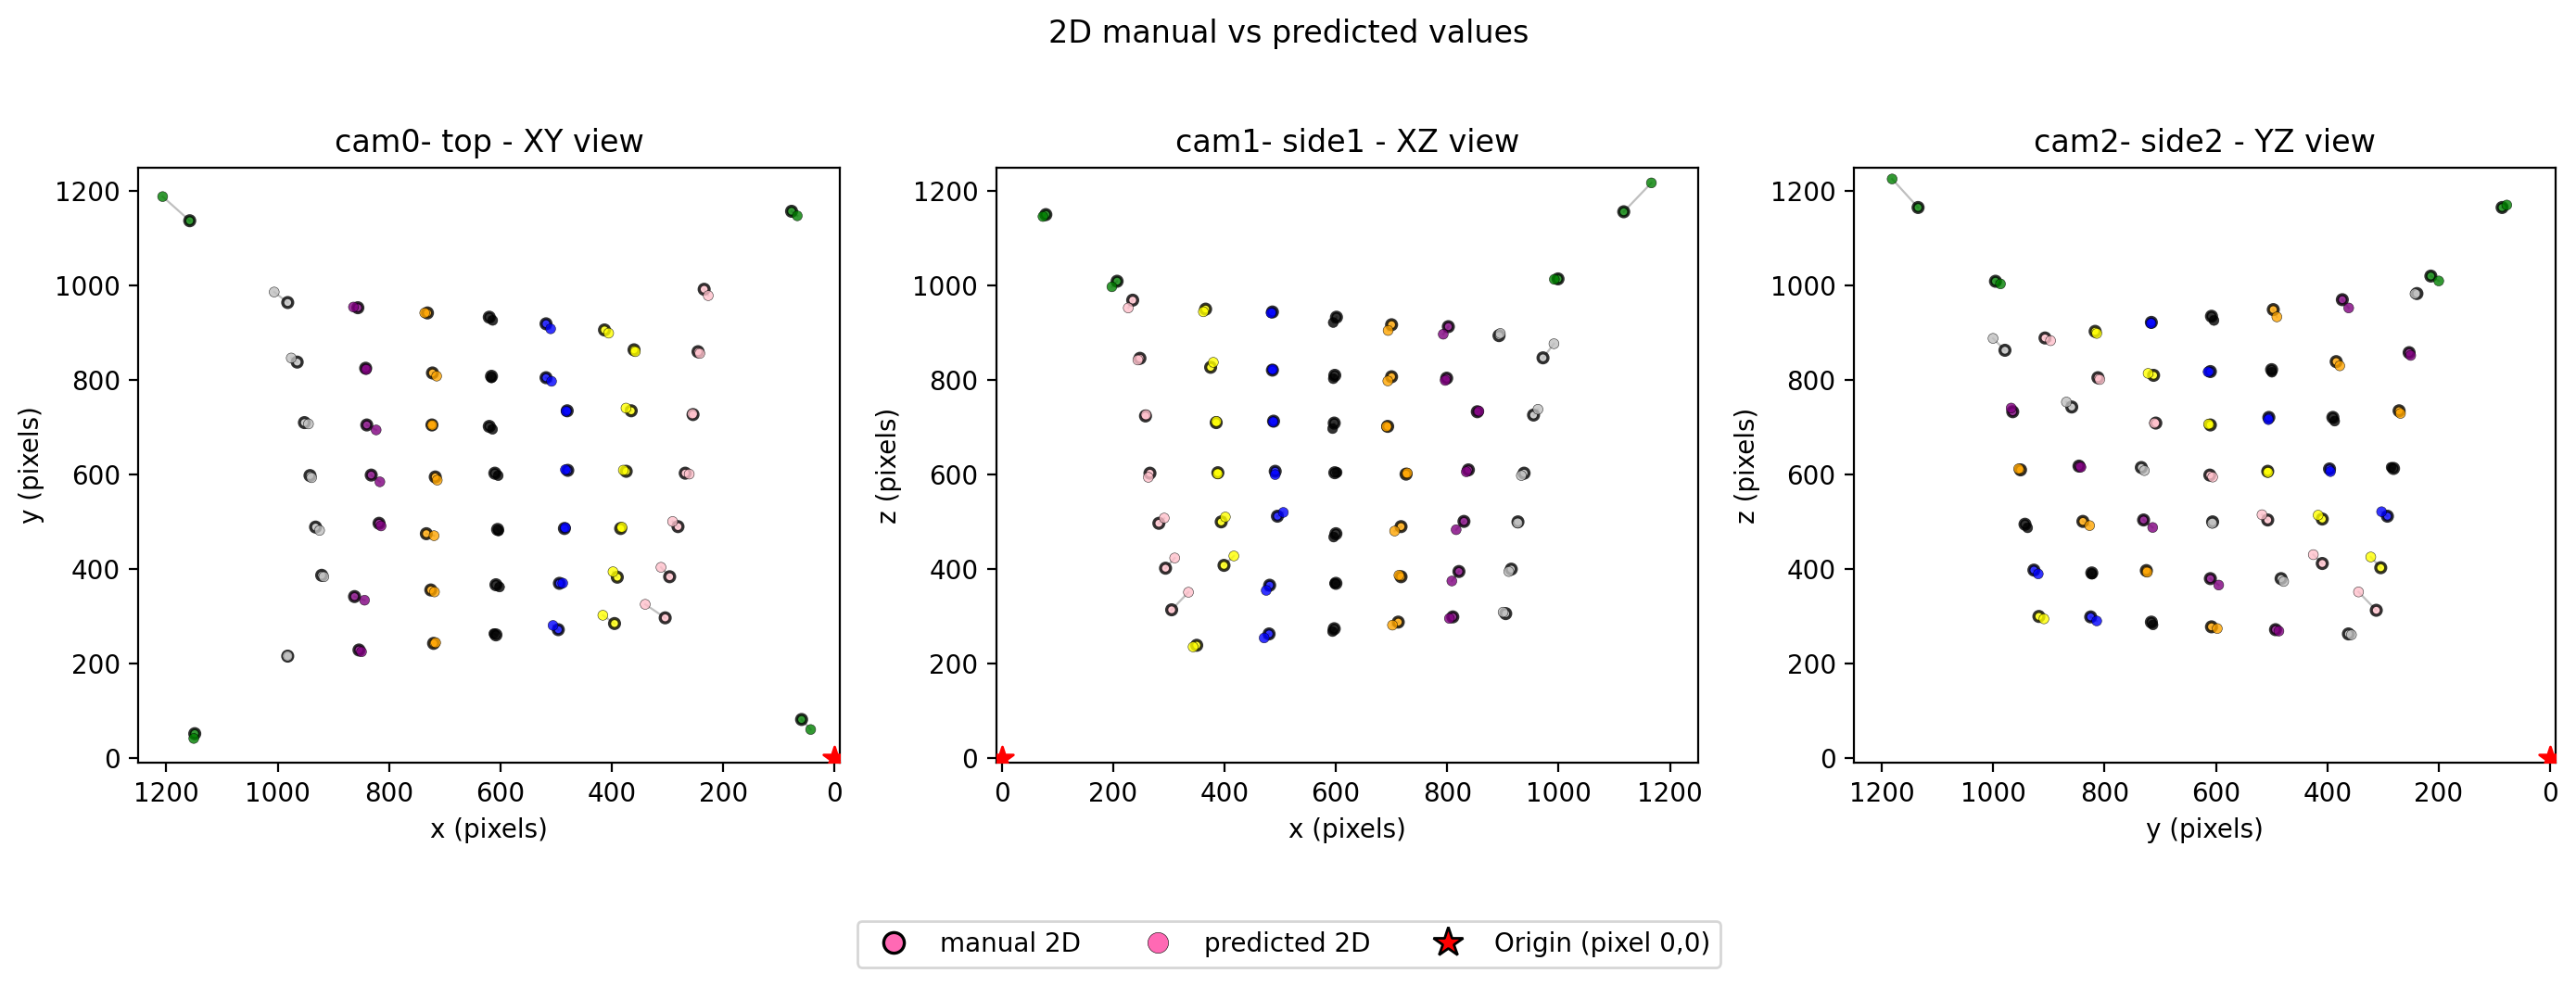

In [3]:
# Step 5b：2D 重投影误差（pred 3D → 2D vs 手动 2D，每相机像素误差）
# 本 cell 可单独运行，请直接修改下方所有路径。只生成一张图（3 张小图 views）。

import subprocess
import sys
from pathlib import Path

# ---------- 请在此指定所有路径 ----------
project_dir = Path(r"D:\medaka-mating-pipeline")
mapping_csv = Path(r"D:\calibration_qc\cali_251217_way1\cali_20251217_point_mapping.csv")
output_views = Path(r"D:\calibration_qc\cali_251217_way1\cali_251217_way1_reprojection_2d_views.png")
# ---------------------------------------

script_path = project_dir / "scripts" / "calibration" / "qc_reprojection_2d.py"
cwd = project_dir.resolve() if project_dir.is_dir() else Path.cwd()
cmd = [
    sys.executable,
    str(script_path),
    "--mapping_csv", str(mapping_csv),
    "--output_views", str(output_views),
]
subprocess.run(cmd, cwd=str(cwd))
print("Step 5b 图已保存到:", output_views)

from IPython.display import Image, display
if output_views.exists():
    display(Image(filename=str(output_views)))
else:
    print("注：图片未生成，请检查 mapping_csv 是否存在：", mapping_csv)